# Prop-Firm Analysis — new_jj

One consistent pipeline built around `new_jj`. Set the knobs in Cell 2, then
**Run All**. Every cell uses the same `bars`, `E`, `g`, and `strat`.


In [1]:
import os, sys
SEARCH_ROOT = r"C:\\Users\\2115h\\Desktop\\Trading"
PROJECT_DIR = next((r for r, d, f in os.walk(SEARCH_ROOT)
                    if "Firms.py" in f and "__pycache__" not in r), os.getcwd())
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: C:\\Users\\2115h\\Desktop\\Trading\Propfirm Convex Analysis\Rules


In [2]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from Firms import FIRMS, get_firm
from Strategy import EmpiricalStrategy
from Backtest import load_ohlc, backtest_entries, ledger_for_rr, measured_winrate
from Analysis import (measured_wr_curve, risk_rr_heatmap, optimal_geometry,
                      plot_risk_curve, plot_equity_paths,
                      optimal_risk_by_firm, days_to_pass_by_firm)
from strategies.new_jj import NewJJ

# ===================== KNOBS =====================
DATA_PATH  = "data/NQ.OHLCV_1min.csv"    # 1-min full-session NQ
FIRM       = get_firm("topstep")
BOS_TF     = "3min"                      # new_jj reversion BOS timeframe
SWING_K    = 2                           # new_jj swing fractal size
K_STOP_ATR = 3                           # SINGLE stop-width value (1R = K_STOP_ATR*ATR)
MAX_HOLD   = 60                          # bars a trade may stay open
RR_GRID    = [0.5, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 2.75, 3.0]
RISK_PCTS  = np.round(np.arange(0.25, 3.51, 0.25), 2)
K_STOP_ATR_GRID = [1, 2, 3, 5, 7, 10]    # only used by the optional sweep (last cell)
# =================================================
ALL_FIRMS = ["apex_eod","apex_intraday","lucid","tradeify_select",
             "tradeify_growth","mffu_rapid","topstep"]
print("Firm:", FIRM.name, "| stop width K =", K_STOP_ATR)

Firm: Topstep (Combine) | stop width K = 3


## Firm rules ($50K)

In [3]:
for k, f in FIRMS.items():
    print(f"{k:17s} {f.name:26s} dd={f.dd_type.value:14s} lock={str(f.trail_lock):7s} "
          f"DLL={str(f.daily_loss_limit):5s}({f.dll_behavior.value:4s}) "
          f"cons={str(f.consistency_pct):4s} min_days={f.min_days}")

apex_eod          Apex (EOD Trailing)        dd=eod_trail      lock=50000   DLL=1000 (hard) cons=None min_days=1
apex_intraday     Apex (Intraday Trailing)   dd=intraday_trail lock=50000   DLL=None (none) cons=None min_days=1
lucid             Lucid (LucidPro)           dd=eod_trail      lock=50000   DLL=1200 (hard) cons=None min_days=1
tradeify_select   Tradeify (Select)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.4  min_days=3
tradeify_growth   Tradeify (Growth)          dd=eod_trail      lock=50000   DLL=1250 (soft) cons=None min_days=1
mffu_rapid        MyFundedFutures (Rapid)    dd=intraday_trail lock=None    DLL=None (none) cons=0.5  min_days=2
topstep           Topstep (Combine)          dd=eod_trail      lock=50000   DLL=None (none) cons=0.5  min_days=2


## 1) Build entries + measured win rate by R:R
`new_jj` on full-session 1-min data (rth_only=False), stop width = `K_STOP_ATR`.
This `E` feeds every cell below.

1253 entries over 752 days (~1.67 trades/day) | new_jj on ?


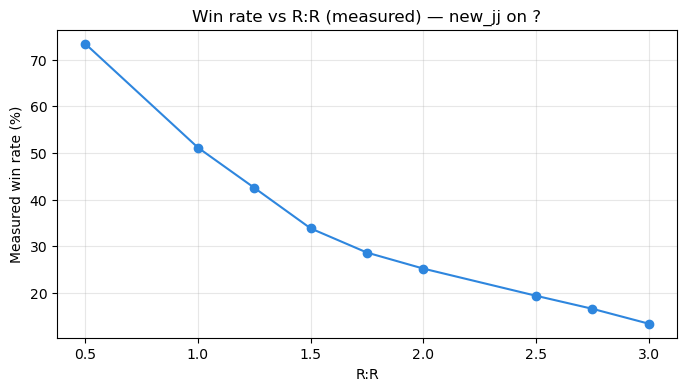

   0.5R  WR=73.4%   edge=+0.110R
   1.0R  WR=51.2%   edge=+0.087R
  1.25R  WR=42.5%   edge=+0.063R
   1.5R  WR=33.8%   edge=+0.038R
  1.75R  WR=28.7%   edge=+0.047R
   2.0R  WR=25.2%   edge=+0.054R
   2.5R  WR=19.4%   edge=+0.074R
  2.75R  WR=16.6%   edge=+0.074R
   3.0R  WR=13.4%   edge=+0.075R


In [4]:
bars = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
# bars = bars.loc["2025-01-01":"2026-12-31"]     # optional holdout window
E = backtest_entries(NewJJ(bos_tf=BOS_TF, swing_k=SWING_K), bars,
                     k_stop_atr=K_STOP_ATR, max_hold=MAX_HOLD)
print(E.summary())
fig, wr_by_rr, edge_by_rr = measured_wr_curve(E, RR_GRID); plt.show()
for rr in RR_GRID:
    print(f"  {rr:>4}R  WR={wr_by_rr[rr]:5.1%}   edge={edge_by_rr[rr]:+.3f}R")

## 2) Optimal risk geometry for the chosen firm

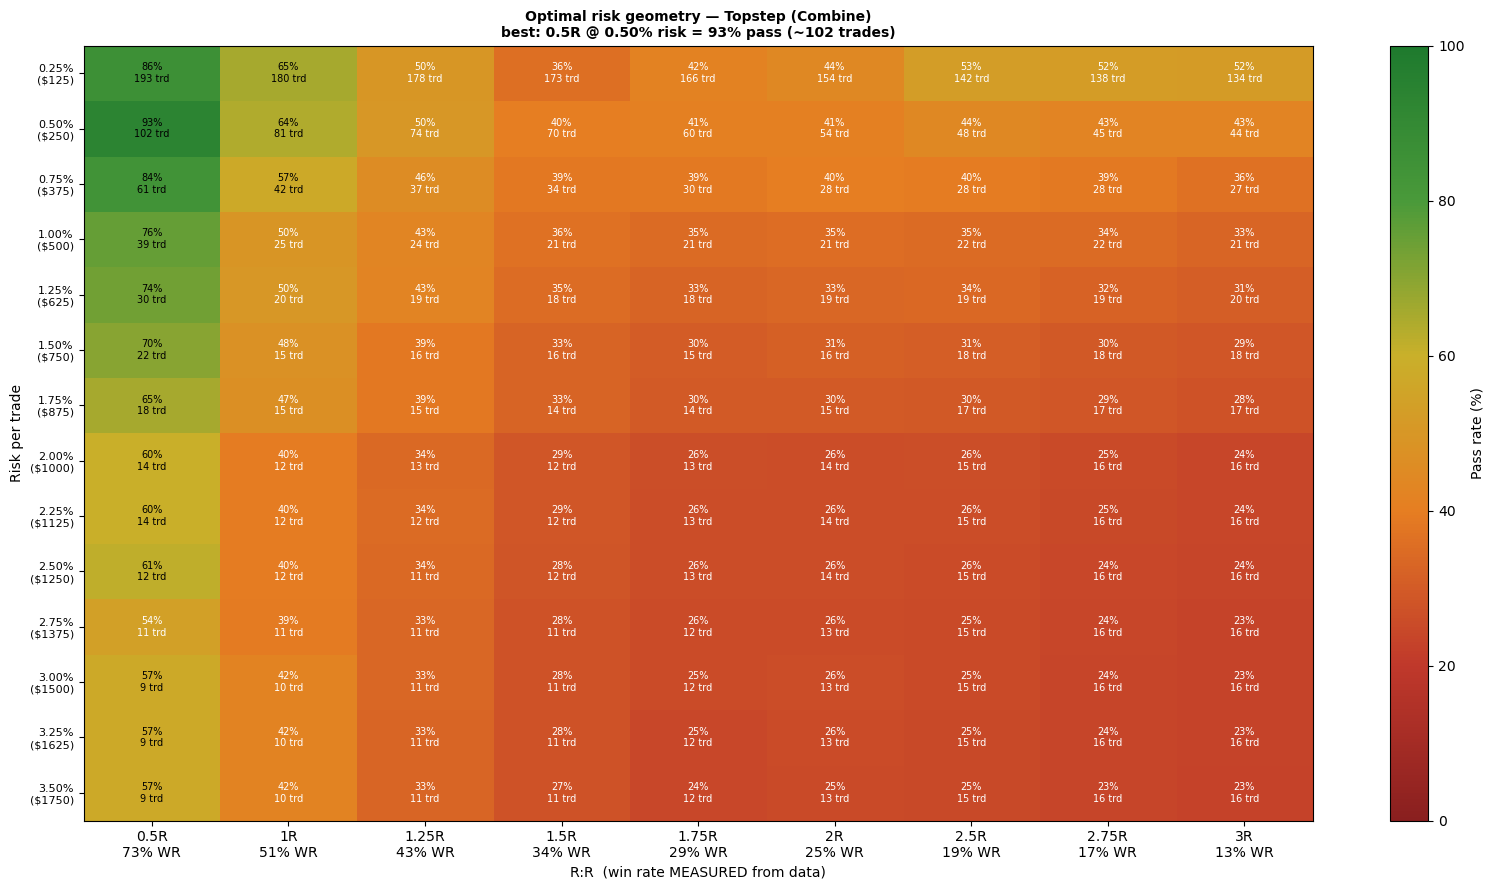

BEST for Topstep (Combine): 0.5R @ 0.50% risk -> 93% pass in ~102 trades (WR 73%)


In [5]:
fig, g = risk_rr_heatmap(FIRM, E, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                         n_paths=2000, max_trades=300); plt.show()
print(f"BEST for {FIRM.name}: {g['opt_rr']:g}R @ {g['opt_risk_pct']:.2f}% risk "
      f"-> {g['opt_pass_pct']:.0f}% pass in ~{g['opt_speed']:.0f} trades (WR {g['opt_wr']:.0%})")

## 3) Risk curve + equity paths at the optimal R:R

In [ ]:
R, days = ledger_for_rr(E, g["opt_rr"])
strat = EmpiricalStrategy(R, name=f"new_jj {g['opt_rr']:g}R (WR {measured_winrate(E, g['opt_rr']):.0%})",
                          day_ids=days)
fig, r = plot_risk_curve(strat, FIRM, risk_pcts=RISK_PCTS, n_paths=3000, max_trades=300); plt.show()
fig = plot_equity_paths(FIRM, strat, risk_per_trade=r["opt_risk_dollars"],
                        n_show=120, max_trades=300); plt.show()

## 4) Cross-firm optimal risk

In [ ]:
results, fig = optimal_risk_by_firm(strat, get_firm, ALL_FIRMS,
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300); plt.show()

## 5) Time to pass by firm

In [ ]:
results, fig, summary = days_to_pass_by_firm(strat, get_firm, ALL_FIRMS,
    risk_pcts=RISK_PCTS, n_paths=2500, max_trades=300, dist_paths=20000); plt.show()
print(summary.to_string(index=False))

## Add-on — sweep stop width (K_STOP_ATR)
Independent of the cells above. Uses `K_STOP_ATR_GRID` from the KNOBS to find the
stop width with the best pass rate for this firm.

In [ ]:
rows = []
for kstop in K_STOP_ATR_GRID:
    Ek = backtest_entries(NewJJ(bos_tf=BOS_TF, swing_k=SWING_K), bars,
                          k_stop_atr=kstop, max_hold=MAX_HOLD)
    if len(Ek.day_ids) < 100:
        print(f"K={kstop}: only {len(Ek.day_ids)} trades — skipping"); continue
    wr1 = (ledger_for_rr(Ek, 1.0)[0] > 0).mean()
    gk = optimal_geometry(FIRM, Ek, risk_pcts=RISK_PCTS, rr_grid=RR_GRID,
                          n_paths=1500, max_trades=300)
    rows.append((kstop, len(Ek.day_ids), wr1*100, gk['opt_rr'], gk['opt_risk_pct'],
                 gk['opt_pass_pct'], gk['opt_speed']))
print(f"\n{'K':>4}{'trades':>8}{'WR@1R':>7}{'RR':>6}{'risk%':>7}{'pass%':>7}{'toPass':>8}")
for row in sorted(rows, key=lambda x: -x[5]):
    print(f"{row[0]:>4}{row[1]:>8}{row[2]:>6.0f}%{row[3]:>6g}{row[4]:>7.2f}{row[5]:>6.0f}%{row[6]:>8.0f}")
if rows:
    plt.figure(figsize=(8,4)); plt.plot([x[0] for x in rows], [x[5] for x in rows], "-o")
    plt.xlabel("K_STOP_ATR"); plt.ylabel("Best pass rate (%)")
    plt.title(f"Pass rate vs stop width — {FIRM.name}"); plt.grid(alpha=.3); plt.show()